# Convolutions

In this lab, we'll look in detail at convolutions and how they can be used to process images.

### Reading and opening images

We'll use the `skimage` library to read and process images. It's a library dedicated to image processing, which is part of the `scikit-learn` family.

In [1]:
## Tensorflow GPU disabled by default. Comment the following lines to enable GPU if you have a working CUDA installation.
import tensorflow as tf

try:
    # Disable all GPUs
    tf.config.set_visible_devices([], 'GPU')

    visible_devices = tf.config.get_visible_devices()
    for device in visible_devices:
        assert device.device_type != 'GPU'
    print("GPUs disabled, using CPU.")

except:
    # Invalid device or cannot modify virtual devices once initialized.
    pass

GPUs disabled, using CPU.


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import skimage

sample image shape:  (400, 600, 3)


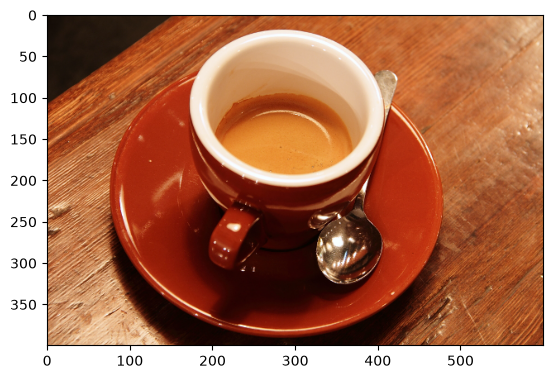

In [3]:
sample_image = skimage.data.coffee()

size = sample_image.shape
print("sample image shape: ", sample_image.shape)

plt.imshow(sample_image.astype('uint8'));

### A simple convolution filter

Before we start working on training any models, let's look at applying a convolution filter to an image. We'll use the `Conv2D` layer from Keras to do this.

In [4]:
from tensorflow.keras.layers import Conv2D

In [5]:
conv = Conv2D(filters=3, kernel_size=(5, 5), padding="same")

Remember: in Keras, `None` is used as a marker for tensor dimensions with dynamic size. In this case `batch_size`, `width` and `height` are all dynamic: they can depend on the input. This is a neat feature of convolutional neural networks: the same model can be used to process images of any size, because all we have to do is slide the convolutional filter across the image as much as necessary.

In [6]:
sample_image.shape

(400, 600, 3)

In [7]:
img_in = np.expand_dims(sample_image, 0).astype(float)
img_in.shape

(1, 400, 600, 3)

In [8]:
img_out = conv(img_in) # Apply the convolutional filter

The output is a tensorflow Eager Tensor - a special data structure that is used to represent the result of operations in TensorFlow. It is not a numpy array, but it can be converted to one using the `.numpy()` method:

In [9]:
np_img_out = img_out[0].numpy()
print(type(np_img_out))
print(np_img_out.shape)

<class 'numpy.ndarray'>
(400, 600, 3)


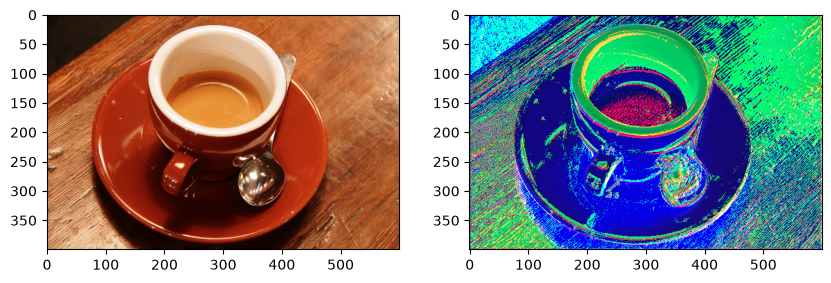

In [10]:
fig, (ax0, ax1) = plt.subplots(ncols=2, figsize=(10, 5))
ax0.imshow(sample_image.astype('uint8'))
ax1.imshow(np_img_out.astype('uint8'));

As we can see, our convolutional filter was initialized randomly, so our output doesn't contain any specific meaning. Each pixel is a random combination of the pixels in the input image, in a 5x5 window.

Let's instead take a look at a convolutional feature with a clear purpose. We can build a kernel ourselves, by defining a function which will be passed to `Conv2D` Layer.
We'll create an array with 1/25 for filters, with each channel seperated. Before you move to the next cell, can you guess what this filter will do?

In [11]:
def my_kernel(shape=(5, 5, 3, 3), dtype=None):
    array = np.zeros(shape=shape, dtype="float32")
    array[:, :, 0, 0] = 1 / 25
    array[:, :, 1, 1] = 1 / 25
    array[:, :, 2, 2] = 1 / 25
    return array

Now we can use this function to initialize a `Conv2D` layer:

In [12]:
conv = Conv2D(filters=3, kernel_size=(5, 5), padding="same", kernel_initializer=my_kernel)

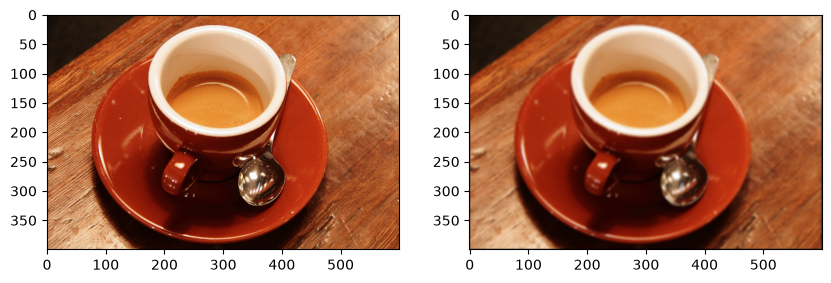

In [13]:
fig, (ax0, ax1) = plt.subplots(ncols=2, figsize=(10, 5))
ax0.imshow(img_in[0].astype('uint8'))

img_out = conv(img_in)
np_img_out = img_out[0].numpy()
ax1.imshow(np_img_out.astype('uint8'));

**Answer:** It is a **blur** (a "box" or mean filter). Each output pixel is the average of the 5×5 = 25 pixels around it, in the same colour channel (red only from red, and so on, because only the `[:, :, c, c]` entries are non-zero). Averaging smooths out fine detail, so the output is a blurrier version of the original with the same colours.

Hopefully you can tell what this filter does!

**Exercise**
- There are a number of settings when we define our Conv2D layer. Try changing the following parameters to get a sense of how they impact the result:
- kernel_size: try different sizes
- padding: try 'valid' instead of 'same' (hint: this may change the size of the output)

input shape: (400, 600, 3)


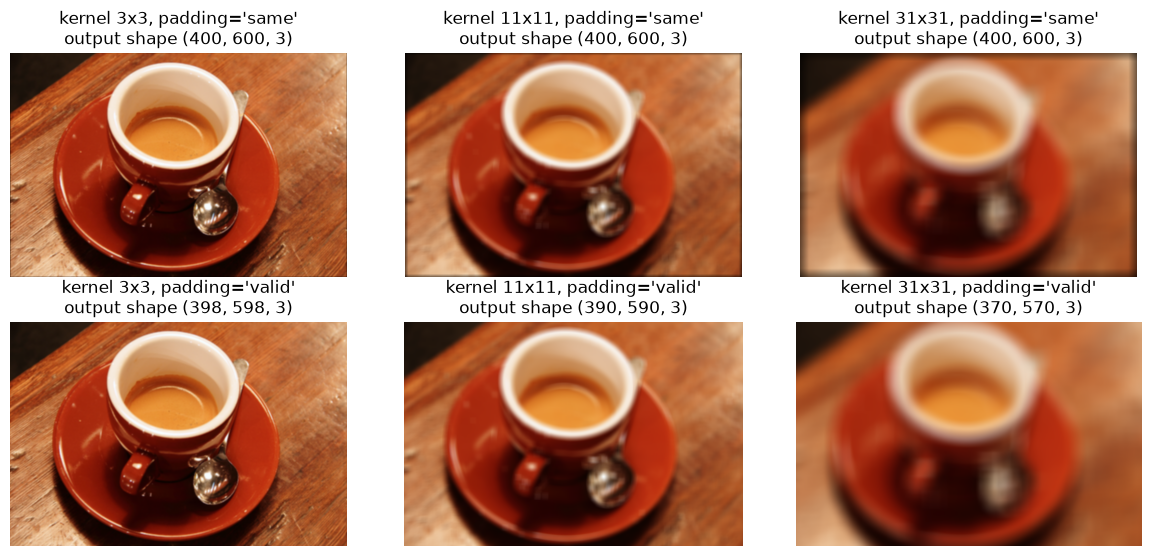

In [14]:
# Your Code Here
def make_blur_kernel(k):
    """k x k averaging kernel that blurs each colour channel separately (same idea as my_kernel above)."""
    def init(shape=(k, k, 3, 3), dtype=None):
        array = np.zeros(shape=shape, dtype="float32")
        for channel in range(3):
            array[:, :, channel, channel] = 1 / (k * k)
        return array
    return init


print("input shape:", img_in.shape[1:])
fig, axes = plt.subplots(2, 3, figsize=(12, 5.6))
for row, padding in enumerate(["same", "valid"]):
    for col, k in enumerate([3, 11, 31]):
        conv = Conv2D(filters=3, kernel_size=(k, k), padding=padding, kernel_initializer=make_blur_kernel(k))
        np_img_out = conv(img_in)[0].numpy()
        axes[row, col].imshow(np_img_out.astype('uint8'))
        axes[row, col].set_title(f"kernel {k}x{k}, padding='{padding}'\noutput shape {np_img_out.shape}")
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

### Working on edge detection on Grayscale image

Using a grayscale image, let's build an "edge detector" using a convolutional filter. Some filters pre-date the deep learning era and are still used today. For example, the Sobel filter is used to detect edges in images. These easy-to-compute filters were used in the early days of computer vision and are still useful now.

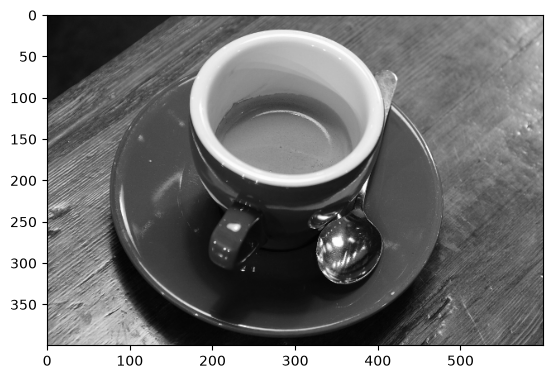

In [15]:
# convert image to greyscale
grey_sample_image = sample_image.mean(axis=2)

# add the channel dimension even if it's only one channel so
# to be consistent with Keras expectations.
grey_sample_image = grey_sample_image[:, :, np.newaxis]

# matplotlib does not like the extra dim for the color channel
# when plotting gray-level images. Let's use squeeze:
plt.imshow(np.squeeze(grey_sample_image.astype(np.uint8)),
           cmap=plt.cm.gray);

**Exercise**
- Build an edge detector using `Conv2D` on greyscale image by defining the kernel inside `my_kernel`.
- You may experiment with several kernels to find a way to detect edges. The following article contains specific examples of kernels that you can use:
- https://en.wikipedia.org/wiki/Kernel_(image_processing)
- Try different kernels and see the impact on the output.

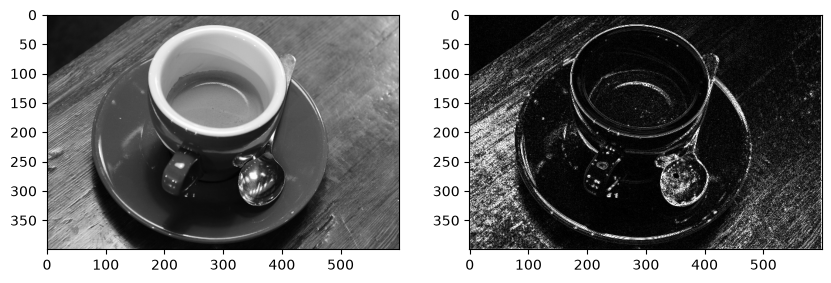

In [16]:
def my_kernel(shape=(3, 3, 1, 1), dtype=None):
    # Laplacian edge detector: 8 x the centre pixel minus its 8 neighbours.
    # On a flat area the result is 0 (black); where the brightness changes (an edge) it is large.
    array = np.array([[-1, -1, -1],
                      [-1,  8, -1],
                      [-1, -1, -1]], dtype="float32")
    array = array.reshape(*shape)
    return array

conv = Conv2D(filters=1, kernel_size=(3, 3), padding="same", kernel_initializer=my_kernel)

img_in = np.expand_dims(grey_sample_image, 0) # Reshape into a batch of size 1
img_out = conv(img_in) # Apply the convolutional filter
np_img_out = img_out[0].numpy() # Convert to numpy array

fig, (ax0, ax1) = plt.subplots(ncols=2, figsize=(10, 5))
ax0.imshow(np.squeeze(grey_sample_image.astype(np.uint8)),
           cmap=plt.cm.gray)
# The filter gives negative values on one side of each edge: take the absolute value and clip to [0, 255]
# (casting negative numbers straight to uint8 would wrap them around to bright values)
ax1.imshow(np.clip(np.abs(np.squeeze(np_img_out)), 0, 255).astype(np.uint8), cmap=plt.cm.gray);

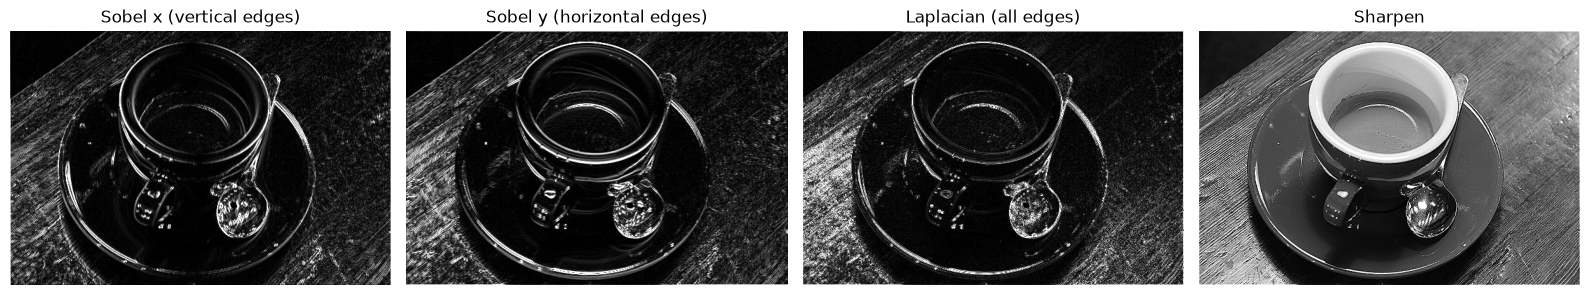

In [17]:
# Trying other kernels: Sobel filters detect vertical and horizontal edges separately
def kernel_from(values):
    """Wrap a 3x3 array as a Keras kernel initializer for a 1-channel Conv2D."""
    def init(shape=(3, 3, 1, 1), dtype=None):
        return np.array(values, dtype="float32").reshape(*shape)
    return init


kernels = {
    "Sobel x (vertical edges)": [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
    "Sobel y (horizontal edges)": [[-1, -2, -1], [0, 0, 0], [1, 2, 1]],
    "Laplacian (all edges)": [[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]],
    "Sharpen": [[0, -1, 0], [-1, 5, -1], [0, -1, 0]],
}
fig, axes = plt.subplots(1, len(kernels), figsize=(16, 3.3))
for ax, (name, values) in zip(axes, kernels.items()):
    conv = Conv2D(filters=1, kernel_size=(3, 3), padding="same", kernel_initializer=kernel_from(values))
    out = np.squeeze(conv(img_in)[0].numpy())
    # edge filters: show the strength of the response; the sharpen filter keeps the image itself
    shown = out if name == "Sharpen" else np.abs(out)
    ax.imshow(np.clip(shown, 0, 255).astype(np.uint8), cmap=plt.cm.gray)
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Pooling and strides with convolutions

**Exercise**
- Use `MaxPool2D` to apply a 2x2 max pool with strides 2 to the image. What is the impact on the shape of the image?
- Use `AvgPool2D` to apply an average pooling.
- Is it possible to compute a max pooling and an average pooling with well chosen kernels?

input shape: (1, 400, 600, 1)
after 2x2 max pooling with strides 2: (200, 300, 1)
after 2x2 average pooling with strides 2: (200, 300, 1)


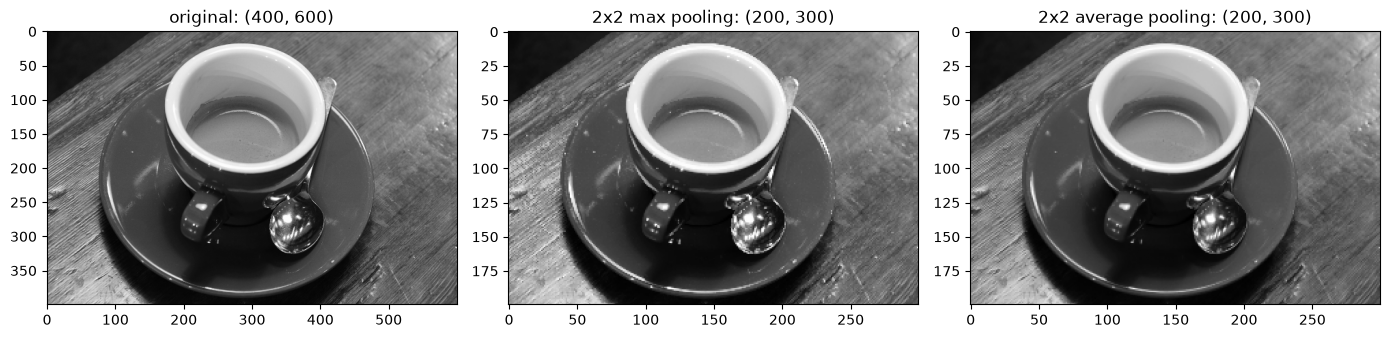

average pooling == convolution with a 1/4 kernel and strides 2: True


In [18]:
from tensorflow.keras.layers import MaxPool2D, AvgPool2D

# You can use `img_in` from above as input to the pooling layers
print("input shape:", img_in.shape)

max_pool = MaxPool2D(pool_size=(2, 2), strides=(2, 2), padding="valid")
max_out = max_pool(img_in)[0].numpy()
print("after 2x2 max pooling with strides 2:", max_out.shape)

avg_pool = AvgPool2D(pool_size=(2, 2), strides=(2, 2), padding="valid")
avg_out = avg_pool(img_in)[0].numpy()
print("after 2x2 average pooling with strides 2:", avg_out.shape)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, (title, img) in zip(axes, [("original", grey_sample_image), ("2x2 max pooling", max_out),
                                   ("2x2 average pooling", avg_out)]):
    ax.imshow(np.squeeze(img.astype(np.uint8)), cmap=plt.cm.gray)
    ax.set_title(f"{title}: {np.squeeze(img).shape}")
plt.tight_layout()
plt.show()

# Average pooling as a convolution: a 2x2 kernel of 1/4 everywhere, applied with strides 2
avg_conv = Conv2D(filters=1, kernel_size=(2, 2), strides=(2, 2), padding="valid", use_bias=False,
                  kernel_initializer=lambda shape, dtype=None: np.full(shape, 1 / 4, dtype="float32"))
print("average pooling == convolution with a 1/4 kernel and strides 2:",
      np.allclose(avg_conv(img_in)[0].numpy(), avg_out, atol=1e-3))

**Answer:**

- **Shape:** 2×2 pooling with strides 2 **halves the height and the width**: 400×600 becomes 200×300 (a quarter of the pixels). The number of channels does not change.
- **Max pooling** keeps the brightest pixel of each 2×2 block, so strong features such as bright edges survive. **Average pooling** keeps the mean of each block, so the result is slightly smoother. At this scale both look like a smaller copy of the image.
- **Can they be done with well-chosen kernels?**
  - **Average pooling: yes.** It is exactly a convolution with a 2×2 kernel of 1/4 everywhere, no bias and strides 2. The check above confirms both give the same result (`True`).
  - **Max pooling: no.** A convolution is a weighted *sum* of the pixels with fixed weights (a linear operation), but the maximum depends on which pixel happens to be largest (a non-linear operation), so no fixed kernel can compute it.

## Loading a JPEG file as a numpy array

Let's use [scikit-image](http://scikit-image.rg) to load the content of a JPEG file into a numpy array:

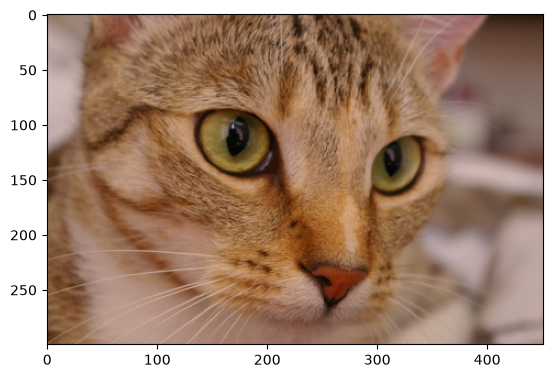

In [19]:
from skimage.io import imread

image = skimage.data.cat()
plt.imshow(image);

## Resizing images, handling data types and dynamic ranges

While convolutions can handle inputs of any size, it is often useful to resize images to a fixed size. This is particularly important for training deep learning models:

- for **image classification**, most networks expect a specific **fixed input size**;

- for **object detection** and instance segmentation, networks have more flexibility but the image should have **approximately the same size as the training set images**.

Furthermore **large images can be much slower to process** than smaller images (the number of pixels varies quadratically with the height and width).

In [20]:
from skimage.transform import resize

lowres_image = resize(image, (50, 50), mode='reflect', anti_aliasing=True)
lowres_image.shape

(50, 50, 3)

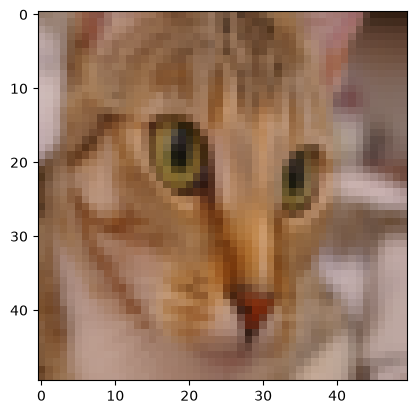

In [21]:
plt.imshow(lowres_image, interpolation='nearest');

The values of the pixels of the low resolution image are computed from by combining the values of the pixels in the high resolution image. The result is therefore represented as floating points.

## Using a pretrained model

Objectives:

- Load a pre-trained ResNet50 pre-trained model using Keras Zoo
- Use the model to classify an image
- Use the model to classify an image from the webcam

Let's start with loading ResNet50, a well-established method for image classification. The ResNet50 "application" takes two key parameters here: firstly, `include_top` indicates whether we want to include the last layer of the network (the classification layer) or not. Secondly, `weights` indicates whether we want to load the weights of a model that has been pre-trained on ImageNet or not.

In [22]:
from tensorflow.keras.applications.resnet50 import ResNet50

model = ResNet50(include_top=True, weights='imagenet')
model.compile(optimizer='sgd', loss='categorical_crossentropy')

In [23]:
print(model.summary())

Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 25,636,712 (97.80 MB)

 Trainable params: 25,583,592 (97.59 MB)

 Non-trainable params: 53,120 (207.50 KB)

None


### Classification of an image

**Exercise**
- Reshape the `cat` image to the shape `(224, 224, 3)` using `resize` from `skimage.transform`
- Use `preprocess_input` from `tensorflow.keras.applications.imagenet_utils` to preprocess the image
- Use `predict` to classify the image

Documentation for each method:
- [resize](https://scikit-image.org/docs/dev/api/skimage.transform.html#skimage.transform.resize)
- [preprocess_input](https://www.tensorflow.org/api_docs/python/tf/keras/applications/resnet/preprocess_input)
- [predict](https://www.tensorflow.org/api_docs/python/tf/keras/Model#predict)

In [24]:
from keras.applications.resnet50 import preprocess_input, decode_predictions

# Resize the image
input_image = resize(image, (224, 224, 3), mode='reflect', anti_aliasing=True)

# Scale to [0, 255] range (resize returns [0, 1])
input_image = input_image * 255

# Prepare for model (add batch dimension)
input_image = np.expand_dims(input_image, axis=0)

# Now use preprocess_input and predict to classify the image
input_image = preprocess_input(input_image)  # RGB -> BGR and subtract the ImageNet channel means, as ResNet50 expects
predictions = model.predict(input_image)
for _, label, probability in decode_predictions(predictions, top=5)[0]:
    print(f"{label:<25} {probability:.3f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Egyptian_cat              0.957
tiger_cat                 0.018
tabby                     0.017
shower_cap                0.005
plastic_bag               0.001


##  Taking snapshots from the webcam

For this section, we will take an image from your laptop webcam and classify it. If you feel uncomfortable doing this section, you can skip it and use a photo of your choice from the web instead.

In [25]:
import cv2

def camera_grab(camera_id=0, fallback_filename=None):
    camera = cv2.VideoCapture(camera_id)
    try:
        # take 10 consecutive snapshots to let the camera automatically tune
        # itself and hope that the contrast and lighting of the last snapshot
        # is good enough.
        for i in range(10):
            snapshot_ok, image = camera.read()
        if snapshot_ok:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        else:
            print("WARNING: could not access camera")
            if fallback_filename:
                image = imread(fallback_filename)
    finally:
        camera.release()
    return image

dtype: uint8, shape: (450, 800, 3), range: (np.uint8(0), np.uint8(255))


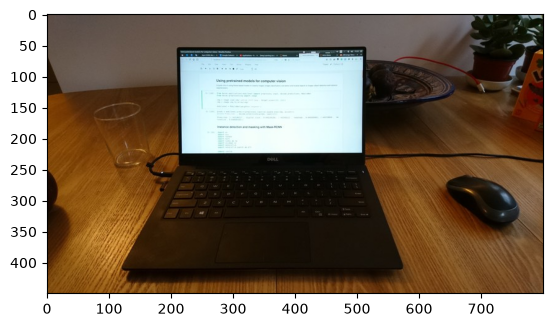

In [26]:
# Instead of the webcam (the lab allows using a photo), classify the laptop photo from the images folder.
# To use your webcam instead: image = camera_grab(camera_id=0, fallback_filename="images/laptop.jpeg")
image = imread("images/laptop.jpeg")
plt.imshow(image)
print("dtype: {}, shape: {}, range: {}".format(
    image.dtype, image.shape, (image.min(), image.max())))

### Exercise

Apply the same preprocessing as before and classify the image. What are your results?

In [27]:
# Apply the same preprocessing as before and classify the webcam image

# Resize the image
input_image = resize(image, (224, 224, 3), mode='reflect', anti_aliasing=True)

# Scale to [0, 255] range (resize returns [0, 1])
input_image = input_image * 255

# Prepare for model (add batch dimension)
input_image = np.expand_dims(input_image, axis=0)

# Now use preprocess_input and predict to classify the image
input_image = preprocess_input(input_image)
predictions = model.predict(input_image)
for _, label, probability in decode_predictions(predictions, top=5)[0]:
    print(f"{label:<25} {probability:.3f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
notebook                  0.404
laptop                    0.291
desk                      0.120
mouse                     0.095
desktop_computer          0.037


**Answer:** I used the laptop photo from the `images` folder instead of the webcam (the lab allows a photo). The top-5 predictions are **notebook (0.404)**, laptop (0.291), desk (0.120), mouse (0.095) and desktop computer (0.037). The model is right: in ImageNet "notebook" means a notebook *computer*, so the top two predictions are both laptops, and the desk and mouse are also in the photo.